# Potato Leaf Disease Detection with a CNN

**Goal:** classify potato leaf photos into **Early blight**, **Late blight** or **Healthy** with a convolutional neural network built in TensorFlow/Keras, so a farmer could catch disease early from a phone photo.

**Headline results**

1. **96.9% test accuracy** (test loss 0.104), which is **248 of 256** held-out images correct, from a small **183,747-parameter** model trained from scratch. *This number is optimistic: see headline 5.*
2. **Learns fast**: both training and validation accuracy pass 95% by **epoch 9**; the remaining 41 epochs mostly refine and stabilise.
3. **Validation is noisy**: validation loss swings between 0.009 and 0.50 across epochs, so the *last* epoch is not the *best* one. This motivates checkpointing and early stopping, now built into `src/potato_cnn.py`.
4. **A sample of 9 unseen leaves was classified 9/9 correctly**, with the lowest confidence (92.1%) on the healthy leaf.
5. **The original split leaked.** An audit that rebuilds the original pipeline shows about **79% of the "test" images (82% with the original seeds) were also in the training set**, so the validation and test scores overstate real performance. The project replaces it with a leak-free split.

> The raw images are not stored in this repository, so everything below comes from the **original training run** (captured in `data/training_history.csv` and `results/`). `train.py` reproduces the experiment on your own copy of the dataset.

## 1. Setup

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display
from src import potato_viz as pv
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
h = pv.load_history(ROOT / "data" / "training_history.csv")
test = json.loads((ROOT / "results" / "original_test_metrics.json").read_text())
print(f"{len(h)} epochs loaded | columns: {list(h.columns)}")

50 epochs loaded | columns: ['epoch', 'seconds', 'accuracy', 'loss', 'val_accuracy', 'val_loss']


## 2. Data and task

The notebook loads images from a `PlantVillage`-style folder with `tf.keras.utils.image_dataset_from_directory` (256x256 RGB, batches of 32). It found **2,152 images in 3 classes**: `Potato___Early_blight`, `Potato___Late_blight`, `Potato___healthy`.

**Dataset split used:** 80% train / 10% validation / 10% test, applied to batches: **54 / 6 / 8 batches of 32**, i.e. about 1,728 training, 192 validation and 256 test images.

**Class balance (worth noticing).** The notebook never counted images per class, but the single inspected batch of 32 labels contained just **one healthy leaf**. That matches the public PlantVillage potato subset, where healthy leaves are a small minority (about 7%). If so, plain accuracy can look strong even when the healthy class is handled poorly, so per-class metrics matter (see section 6).

Training images were augmented on the fly (random flips and rotations of up to 20%), and pixel values were rescaled to 0-1 *inside* the model so deployment needs no separate preprocessing.

## 3. Model

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (32, 256, 256, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (32, 254, 254, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (32, 127, 127, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (32, 125, 125, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (32, 62, 62, 64)       │             0 │
├─────────────────────────────────┼──────────────────

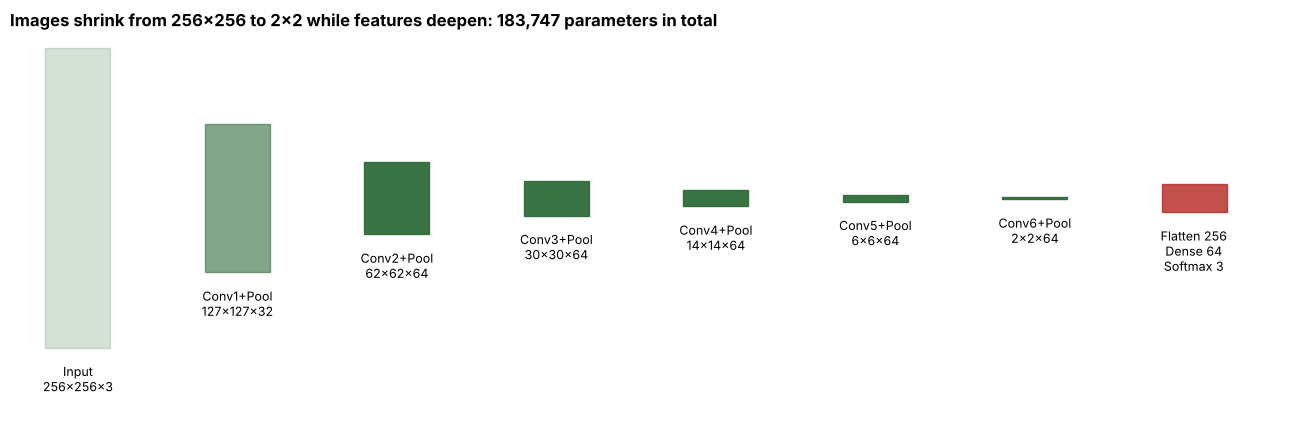

In [2]:
print((ROOT / "results" / "model_summary.txt").read_text())
pv.plot_architecture();

**Insight - small and efficient.** Six convolution + max-pooling blocks shrink a 256x256 photo to a 2x2 feature map (256 numbers), followed by a 64-unit dense layer and a 3-way softmax. At **183,747 parameters (about 718 KB)** it is tiny next to typical image models, and it still reached ~97%. Plant-disease images taken against a plain background are a comparatively easy visual task, which explains why a small network is enough.

## 4. Training behaviour

first epoch with train AND val accuracy >= 95%: 9
best validation accuracy: 0.9948 at epoch(s) [28, 36, 39, 40, 42, 45]
best validation loss:     0.0093 at epoch 42
final epoch: train acc 0.9913, val acc 0.9740, val loss 0.0761
last 10 epochs: train acc 0.9868 vs val acc 0.9735 (gap 1.3 pts)

epochs where validation loss spiked above 0.3:


,val_accuracy,val_loss
epoch,,
7,0.8646,0.3530
16,0.8958,0.3638
30,0.8542,0.4957
41,0.8802,0.3491


total training time: 48.6 min (58 s per epoch, CPU)


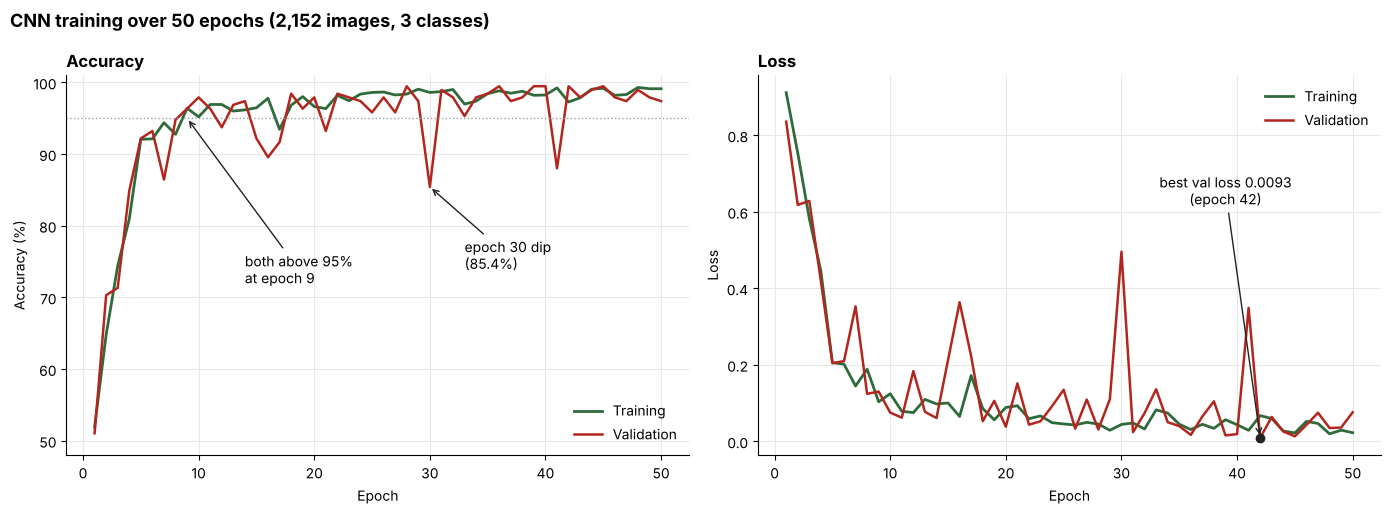

In [3]:
pv.plot_history(h);
best_acc, best_loss = h.val_accuracy.max(), h.val_loss.min()
print(f"first epoch with train AND val accuracy >= 95%: {int(h.epoch[(h.accuracy>=.95)&(h.val_accuracy>=.95)].min())}")
print(f"best validation accuracy: {best_acc:.4f} at epoch(s) {h.epoch[h.val_accuracy==best_acc].tolist()}")
print(f"best validation loss:     {best_loss:.4f} at epoch {int(h.epoch[h.val_loss.idxmin()])}")
print(f"final epoch: train acc {h.accuracy.iloc[-1]:.4f}, val acc {h.val_accuracy.iloc[-1]:.4f}, val loss {h.val_loss.iloc[-1]:.4f}")
last = h.tail(10)
print(f"last 10 epochs: train acc {last.accuracy.mean():.4f} vs val acc {last.val_accuracy.mean():.4f} (gap {(last.accuracy-last.val_accuracy).mean()*100:.1f} pts)")
spikes = h[(h.epoch > 5) & (h.val_loss > 0.3)][["epoch", "val_accuracy", "val_loss"]]
print("\nepochs where validation loss spiked above 0.3:"); display(spikes.round(4).set_index("epoch"))
print(f"total training time: {h.seconds.sum()/60:.1f} min ({h.seconds.mean():.0f} s per epoch, CPU)")

**Insights**

- **Fast learner.** From 52% in epoch 1 to above 95% (train *and* validation) by **epoch 9**.
- **Healthy fit, not heavy overfitting.** Over the last 10 epochs training accuracy averages ~98.7% and validation ~97.3%, a gap of only about 1-2 points.
- **Unstable validation.** Validation loss spikes several times (epochs 7, 16, 30 and 41, up to ~0.50) and validation accuracy dips as low as **85.4%** at epoch 30, even though training is smooth. The validation set is only 192 images, so a handful of mistakes moves accuracy by several points, and augmented training with a constant learning rate adds noise.
- **The last epoch is not the best one.** The lowest validation loss (0.0093) occurs at **epoch 42**, yet the notebook kept the weights from epoch 50 (validation loss 0.076). Keeping the best checkpoint, as `train.py` now does, would have been free accuracy.
- **Cost.** About **49 minutes** on CPU (roughly 58 s per epoch). Early stopping would have cut most of that.

## 5. Test performance and predictions

test accuracy 0.96875  |  test loss 0.1037  |  8 batches of 32
= 248 of 256 images correct, 8 misclassified


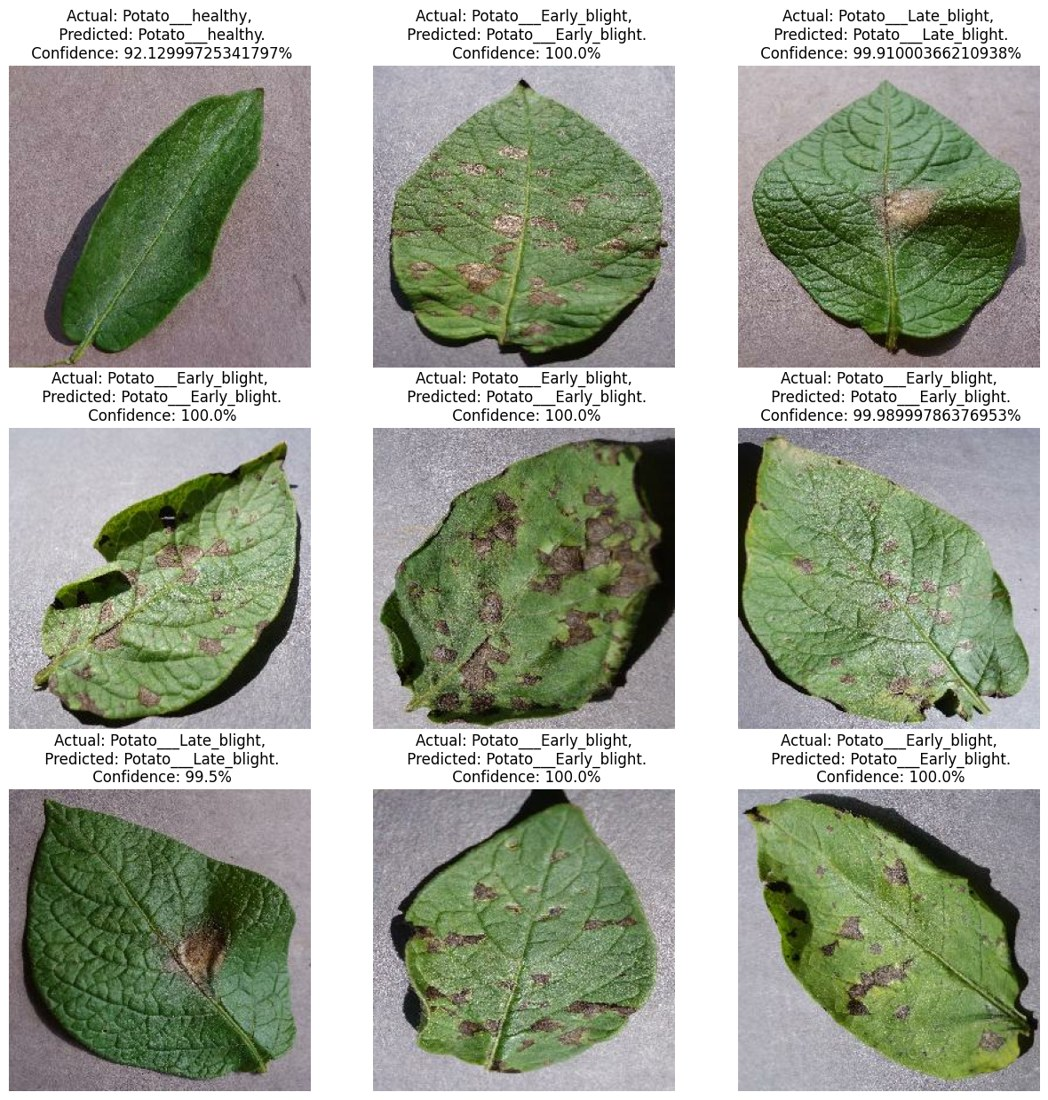

In [4]:
n = round(test["test_accuracy"] * 256)
print(f"test accuracy {test['test_accuracy']:.5f}  |  test loss {test['test_loss']:.4f}  |  {test['n_test_batches']} batches of 32")
print(f"= {n} of 256 images correct, {256-n} misclassified")
display(Image(filename=str(ROOT / "figures" / "03_sample_predictions.jpg")))

**Insight.** Test accuracy is **96.875%**: 248 of 256 images right (exactly 8 errors; this only works out as a whole number if all eight test batches were full, so the test set held 256 images). On the 9 sample leaves shown, all predictions were correct, with confidence between **92.1% and 100%**. The *healthy* leaf had the lowest confidence (92.1%), a hint that this smaller class is the one the model is least sure about, which a confusion matrix would confirm or refute.

**Caveat:** this score was measured on the original split, which the audit in section 6 shows was not leak-free, so read it as an upper bound rather than expected real-world accuracy.

## 6. Issues found in the original pipeline (and how this project fixes them)

| # | Issue in the original notebook | Why it matters | Fix in `src/potato_cnn.py` |
|---|---|---|---|
| 1 | Train/val/test were made with `take()`/`skip()` on a dataset that **reshuffles on every pass**, then cached separately | Each split can be drawn from a *different* shuffle, so images may appear in more than one split (**data leakage**, which inflates validation and test accuracy). **Measured by the audit below: about 79% of "test" images were also in training.** | Split **file paths once**, stratified by class, with fixed seeds; the tests assert the three sets are disjoint |
| 2 | Only overall accuracy reported | The healthy class is small; accuracy can hide weak per-class results | Per-class precision/recall/F1 and a confusion matrix are saved after training |
| 3 | `predict(img)` ignored its argument and read a global `images[i]` | It only worked because of the surrounding loop; calling it on a new photo would return the wrong answer | `predict()` uses the image it is given (file path or array) |
| 4 | Fixed 50 epochs, last weights kept | Best validation loss was at epoch 42, final weights were worse; ~49 min of CPU time | `EarlyStopping` (patience 8, restores best weights) + best-model checkpoint |
| 5 | No model saved | The trained network could not be reused or deployed | Best model saved to `best_model.keras` |
| 6 | Batch size passed inside `input_shape` | Works but is non-standard and triggers warnings | Plain `Input(shape=(256, 256, 3))` |

The new module was tested end to end on synthetic images (not real data) to confirm it runs, that the architecture has exactly **183,747 parameters** like the original, and that the splits do not overlap.

### Audit: how leaky was the original split?

`scripts/audit_split_leakage.py` rebuilds the original `take()`/`skip()` pipeline on synthetic images with unique pixel IDs (1,000 / 1,000 / 152 files, 68 batches of 32), iterates it in the order `fit()` and `evaluate()` would, and counts images present in more than one split.


Original seeds (123, 12): 81.6% of test images and 81.8% of validation images were also in the training set
Mean over 5 seed pairs: 78.6% (test), 77.3% (validation)


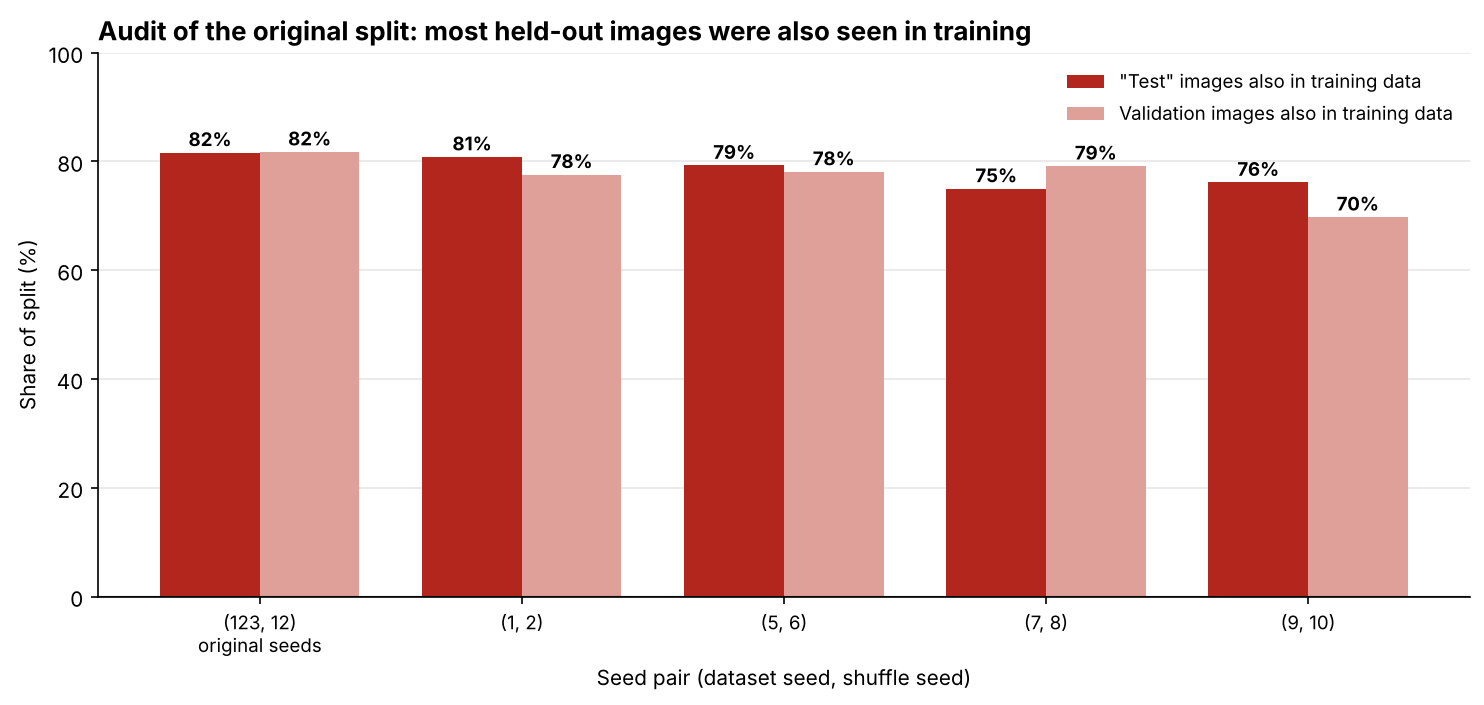

In [5]:
audit = json.loads((ROOT / "results" / "split_leakage_audit.json").read_text())
orig = audit["trials"][0]
print(f"Original seeds {tuple(orig['seeds'])}: {orig['test_in_train']:.1%} of test images and {orig['val_in_train']:.1%} of validation images were also in the training set")
print(f"Mean over {len(audit['trials'])} seed pairs: {audit['mean_test_in_train']:.1%} (test), {audit['mean_val_in_train']:.1%} (validation)")
display(Image(filename=str(ROOT / "figures" / "04_split_leakage_audit.png")))

## 7. Reproduce and extend

```bash
pip install -r requirements.txt
python train.py --data-dir path/to/PlantVillage --epochs 50      # leak-free split, early stopping
python tests/test_pipeline.py                                     # synthetic-data smoke tests
python scripts/audit_split_leakage.py                             # reproduces the split-overlap audit
```

**Limitations:** results come from one run with one split and no repeated trials; the original run's split overlap (about 79%, audited on synthetic images) inflates its scores and the leak-free pipeline has not yet been trained on the real images; class counts and per-class metrics were not recorded; leaves are photographed on plain backgrounds, so real field photos may be harder.

**Next steps:** re-train with the leak-free split and report a confusion matrix; compare against transfer learning (e.g. MobileNetV2); add Grad-CAM heat maps to show *where* the model looks; export to TensorFlow Lite or an API for a mobile app.